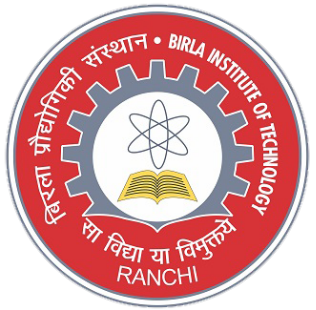

# Tesla Financial Analysis & Valuation
### A runnable Python portfolio notebook

**Birla Institute of Technology, Mesra | Bachelor of Business Administration**

**Report authors:** Kanishk Raj, Abhishek Kashyap and Harsh Parashar  
**Notebook edition:** 30 March 2022  
**Historical data window:** 2012–2020

This notebook turns the supplied Tesla report into editable data tables, reproducible calculations,
charts, and valuation scenarios. All data and the institution logo are embedded in this file.

**Data basis:** Historical numbers and illustrative forecasts were transcribed from the supplied report.
They have not been independently reconciled to original filings. Model outputs are assumption-based
scenario results, not current market estimates. The original report figures are retained where useful
for comparison, and calculation differences are explained.

## How to use this notebook

1. Open the `.ipynb` file in Jupyter Notebook, JupyterLab, VS Code or Google Colab.
2. Use **Run All** to reproduce the tables and charts. Saved outputs are already included.
3. Edit the **assumptions** cells, then rerun the following cells to explore another scenario.
4. The optional final export cell can save CSV tables and PNG charts to a local folder.

Python packages: `numpy`, `pandas`, `matplotlib`, `IPython` and `jinja2` for formatted tables.
If needed, install them in a separate notebook cell with:

```python
%pip install numpy pandas matplotlib ipython jinja2
```

The analysis itself makes no network requests and requires no API keys or additional data files.

### Contents

1. Setup and embedded historical data
2. Data checks, revenue, profitability and operating leverage
3. Cash flow, liquidity and regulatory credits
4. Peer comparison
5. DCF assumptions, forecast engine and reconciliation
6. Sensitivity analysis and the autonomy scenario
7. Pie charts, compute economics and hardware costs
8. Strategic context, risks, conclusions and optional exports

## 1. Setup and embedded historical data

Financial amounts are **USD millions** unless a column or chart explicitly says otherwise.
Share counts are **millions of shares**, so dividing equity value by shares gives **USD per share**.
Percentages in the raw historical table are percentage points; model rate inputs use decimals.

In [1]:
from io import StringIO
from pathlib import Path
from copy import deepcopy
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display, Markdown
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

TEAL = '#087E8B'
NAVY = '#17354B'
AMBER = '#B97A21'
PURPLE = '#7270B1'
PALE_TEAL = '#76A9AC'
RED = '#B44949'
PALETTE = [TEAL, NAVY, AMBER, PURPLE, PALE_TEAL]

plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 120,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.labelcolor': NAVY,
    'font.size': 10, 'axes.grid': False,
    'savefig.facecolor': 'white',
})
pd.options.display.max_columns = 30
FIGURES = {}

def show_table(frame, title=None, precision=2):
    if title:
        display(Markdown(f'**{title}**'))
    display(frame.style.format(precision=precision, thousands=',', na_rep='—'))

def show_figure(name, fig):
    FIGURES[name] = fig
    plt.show()
    plt.close(fig)

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}')

Python 3.12.14 | pandas 2.2.3 | numpy 2.3.5 | matplotlib 3.10.8


In [2]:
DATA_CSV = """
year,revenue,automotive_sales,regulatory_credits,energy_revenue,services_revenue,cost_of_revenue,automotive_cost_of_sales,gross_profit,reported_gross_margin_pct,research_and_development,selling_general_admin,operating_expenses,operating_income,reported_operating_margin_pct,interest_expense,other_income_expense,pretax_income,income_tax,net_income,operating_cash_flow,investing_cash_flow,capex_outflow,financing_cash_flow,reported_free_cash_flow,cash_and_equivalents
2012,413.26,385.69,40.5,0.0,27.57,383.22,357.54,30.04,7.27,273.98,150.37,424.35,-394.31,-95.41,-0.4,0.0,-396.21,0.0,-396.21,-266.0,-206.0,-239.2,418.0,-505.2,201.0
2013,2013.5,1940.47,194.4,0.0,73.03,1557.24,1496.88,456.26,22.66,231.98,285.6,517.58,-61.32,-3.05,-32.93,0.0,-73.54,0.0,-74.01,258.0,-249.0,-264.2,635.0,-6.2,846.0
2014,3198.36,3006.84,216.3,0.0,191.52,2316.69,2185.34,881.67,27.57,464.7,603.67,1068.37,-186.7,-5.84,-100.89,0.0,-284.59,0.0,-294.04,-57.3,-990.0,-969.9,2143.0,-1027.2,1906.0
2015,4046.03,3740.97,168.7,14.48,290.58,3122.52,2823.31,923.51,22.83,717.9,922.23,1640.13,-716.62,-17.71,-118.85,0.0,-875.58,0.0,-888.66,-524.5,-1673.7,-1634.9,1524.0,-2159.4,1197.0
2016,7000.13,6352.56,302.3,181.39,466.18,5400.88,4778.0,1599.25,22.85,834.41,1432.19,2266.6,-667.35,-9.53,-198.81,74.7,-746.34,26.7,-674.91,-123.8,-1416.3,-1284.7,3744.0,-1408.5,3393.0
2017,11758.75,10211.6,360.3,1116.27,787.48,9536.26,8438.0,2222.49,18.9,1378.07,2476.5,3854.57,-1632.08,-13.88,-471.26,28.7,-2051.64,31.55,-1961.4,-60.6,-4418.9,-3414.8,4415.0,-3475.4,3368.0
2018,21461.27,18506.0,418.6,1555.0,1391.0,17419.0,14640.0,4042.27,18.83,1460.0,2834.0,4294.0,-251.73,-1.17,-663.0,-42.0,-1005.0,58.0,-976.0,2097.8,-2337.0,-2100.7,574.0,-2.9,3686.0
2019,24578.0,20872.0,594.0,1531.0,2226.0,20509.0,16984.0,4069.0,16.56,1343.0,2646.0,3989.0,-69.0,-0.28,-685.0,45.0,-767.0,110.0,-862.0,2405.0,-1437.0,-1327.0,1529.0,1078.0,6268.0
2020,31536.0,27238.0,1580.0,1994.0,2306.0,24906.0,20288.0,6630.0,21.02,1491.0,3145.0,4636.0,1994.0,6.32,-748.0,-85.0,1154.0,292.0,690.0,5943.0,-3132.0,-3157.0,9973.0,2786.0,19384.0
"""

historical_raw = pd.read_csv(StringIO(DATA_CSV), dtype={"year": "int64"})
historical = historical_raw.sort_values("year").set_index("year").copy()
show_table(historical.T, "Source data — USD millions, except reported margin columns")

**Source data — USD millions, except reported margin columns**

year,2012,2013,2014,2015,2016,2017,2018,2019,2020
revenue,413.26,"2,013.50","3,198.36","4,046.03","7,000.13","11,758.75","21,461.27","24,578.00","31,536.00"
automotive_sales,385.69,"1,940.47","3,006.84","3,740.97","6,352.56","10,211.60","18,506.00","20,872.00","27,238.00"
regulatory_credits,40.50,194.40,216.30,168.70,302.30,360.30,418.60,594.00,"1,580.00"
energy_revenue,0.00,0.00,0.00,14.48,181.39,"1,116.27","1,555.00","1,531.00","1,994.00"
services_revenue,27.57,73.03,191.52,290.58,466.18,787.48,"1,391.00","2,226.00","2,306.00"
cost_of_revenue,383.22,"1,557.24","2,316.69","3,122.52","5,400.88","9,536.26","17,419.00","20,509.00","24,906.00"
automotive_cost_of_sales,357.54,"1,496.88","2,185.34","2,823.31","4,778.00","8,438.00","14,640.00","16,984.00","20,288.00"
gross_profit,30.04,456.26,881.67,923.51,"1,599.25","2,222.49","4,042.27","4,069.00","6,630.00"
reported_gross_margin_pct,7.27,22.66,27.57,22.83,22.85,18.90,18.83,16.56,21.02
research_and_development,273.98,231.98,464.70,717.90,834.41,"1,378.07","1,460.00","1,343.00","1,491.00"


### Data definitions and boundaries

- `regulatory_credits` is a component of automotive revenue. It must not be added again to total revenue.
- `capex_outflow` is negative in the source cash-flow table; `capex_spend` below converts it to a positive expense amount.
- `reported_*` columns preserve the original report; separately calculated columns remain distinct.
- Current assets, current liabilities and a complete annual debt series are not supplied. Therefore,
  the notebook does not invent current ratios, quick ratios or annual debt-to-equity ratios.

In [3]:
# Validate the structure before calculating metrics.
assert historical.index.is_unique, 'Each year must have only one observation.'
assert historical.index.is_monotonic_increasing
assert historical.index.dtype.kind in 'iu'
assert np.isfinite(historical.to_numpy(dtype=float)).all()
assert historical['revenue'].gt(0).all()
assert historical['capex_outflow'].le(0).all()

historical['capex_spend'] = -historical['capex_outflow']
historical['free_cash_flow'] = historical['operating_cash_flow'] - historical['capex_spend']
historical['revenue_growth_pct'] = historical['revenue'].pct_change() * 100
for label, numerator in [('gross_margin_pct', 'gross_profit'),
                         ('operating_margin_pct', 'operating_income'),
                         ('net_margin_pct', 'net_income'),
                         ('opex_to_revenue_pct', 'operating_expenses'),
                         ('rnd_to_revenue_pct', 'research_and_development'),
                         ('sga_to_revenue_pct', 'selling_general_admin')]:
    historical[label] = historical[numerator] / historical['revenue'] * 100

reconciliation = pd.DataFrame({
    'Gross profit residual (USD M)': historical['gross_profit'] -
        (historical['revenue'] - historical['cost_of_revenue']),
    'Operating income residual (USD M)': historical['operating_income'] -
        (historical['gross_profit'] - historical['operating_expenses']),
    'FCF residual (USD M)': historical['reported_free_cash_flow'] - historical['free_cash_flow'],
    'Gross margin residual (pp)': historical['reported_gross_margin_pct'] - historical['gross_margin_pct'],
    'Operating margin residual (pp)': historical['reported_operating_margin_pct'] - historical['operating_margin_pct'],
})
show_table(reconciliation, 'Arithmetic checks: reported minus calculated', precision=4)
print(f'{len(historical)} annual observations; {historical_raw.isna().sum().sum()} missing source cells.')
print('Small residuals may reflect rounding. These checks do not verify the source against SEC filings.')

9 annual observations; 0 missing source cells.
Small residuals may reflect rounding. These checks do not verify the source against SEC filings.


**Arithmetic checks: reported minus calculated**

,Gross profit residual (USD M),Operating income residual (USD M),FCF residual (USD M),Gross margin residual (pp),Operating margin residual (pp)
year,,,,,
2012,0.0000,0.0000,0.0000,0.0010,0.0045
2013,0.0000,0.0000,-0.0000,-0.0000,-0.0046
2014,-0.0000,-0.0000,0.0000,0.0037,-0.0026
2015,-0.0000,0.0000,0.0000,0.0049,0.0017
2016,0.0000,-0.0000,0.0000,0.0040,0.0034
2017,0.0000,0.0000,0.0000,-0.0007,-0.0003
2018,-0.0000,0.0000,-0.0000,-0.0052,0.0030
2019,0.0000,-149.0000,0.0000,0.0045,0.0007
2020,0.0000,0.0000,0.0000,-0.0036,-0.0029


## 2. Revenue, profitability and operating leverage

The compound annual growth rate uses the elapsed number of years between the first and last observation.
It does not use the number of rows as the exponent denominator.

**Historical summary from the supplied data**

,Calculated value
First year revenue (USD M),413.26
Last year revenue (USD M),"31,536.00"
Revenue CAGR (%),71.92
2020 net income (USD M),690.00
2020 free cash flow (USD M),"2,786.00"
2020 cash and equivalents (USD M),"19,384.00"


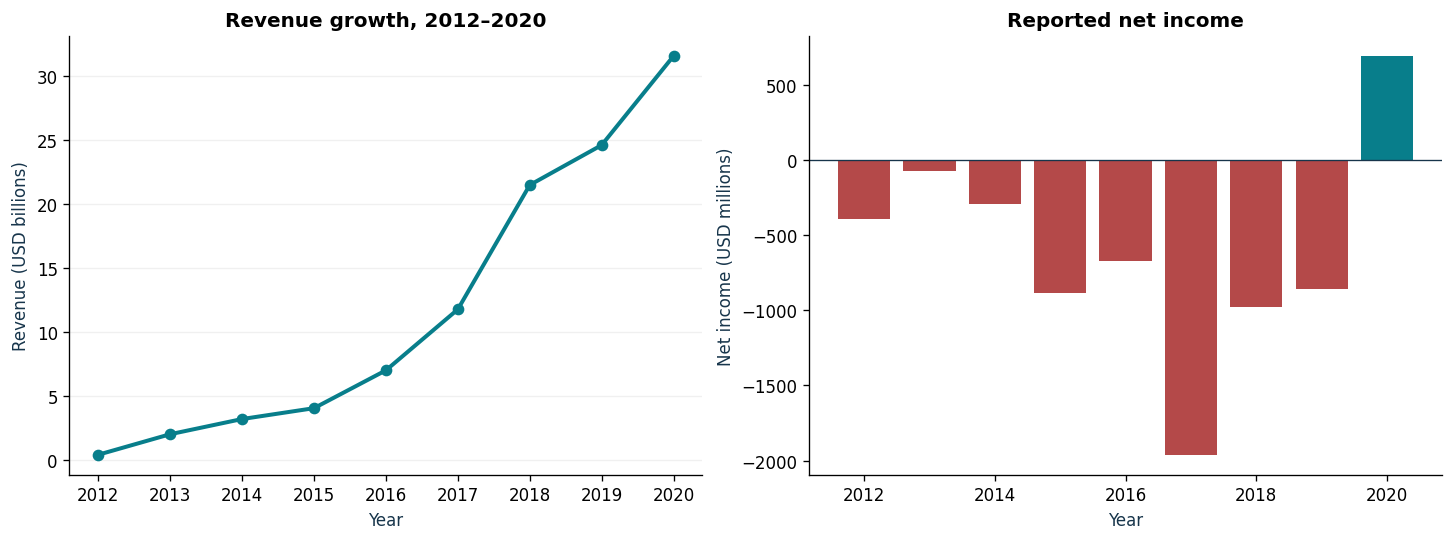

In [4]:
start_year, end_year = int(historical.index.min()), int(historical.index.max())
elapsed_years = end_year - start_year
revenue_cagr = (historical.loc[end_year, 'revenue'] / historical.loc[start_year, 'revenue']) ** (1 / elapsed_years) - 1
summary = pd.Series({
    'First year revenue (USD M)': historical.loc[start_year, 'revenue'],
    'Last year revenue (USD M)': historical.loc[end_year, 'revenue'],
    'Revenue CAGR (%)': revenue_cagr * 100,
    '2020 net income (USD M)': historical.loc[2020, 'net_income'],
    '2020 free cash flow (USD M)': historical.loc[2020, 'free_cash_flow'],
    '2020 cash and equivalents (USD M)': historical.loc[2020, 'cash_and_equivalents'],
}, name='Calculated value')
show_table(summary.to_frame(), 'Historical summary from the supplied data')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained')
axes[0].plot(historical.index, historical['revenue'] / 1000, color=TEAL, marker='o', linewidth=2.4)
axes[0].set(title='Revenue growth, 2012–2020', xlabel='Year', ylabel='Revenue (USD billions)')
axes[0].grid(axis='y', alpha=.18)
net = historical['net_income']
axes[1].bar(historical.index, net, color=[TEAL if x >= 0 else RED for x in net])
axes[1].axhline(0, color=NAVY, linewidth=.8)
axes[1].set(title='Reported net income', xlabel='Year', ylabel='Net income (USD millions)')
show_figure('revenue_and_net_income', fig)

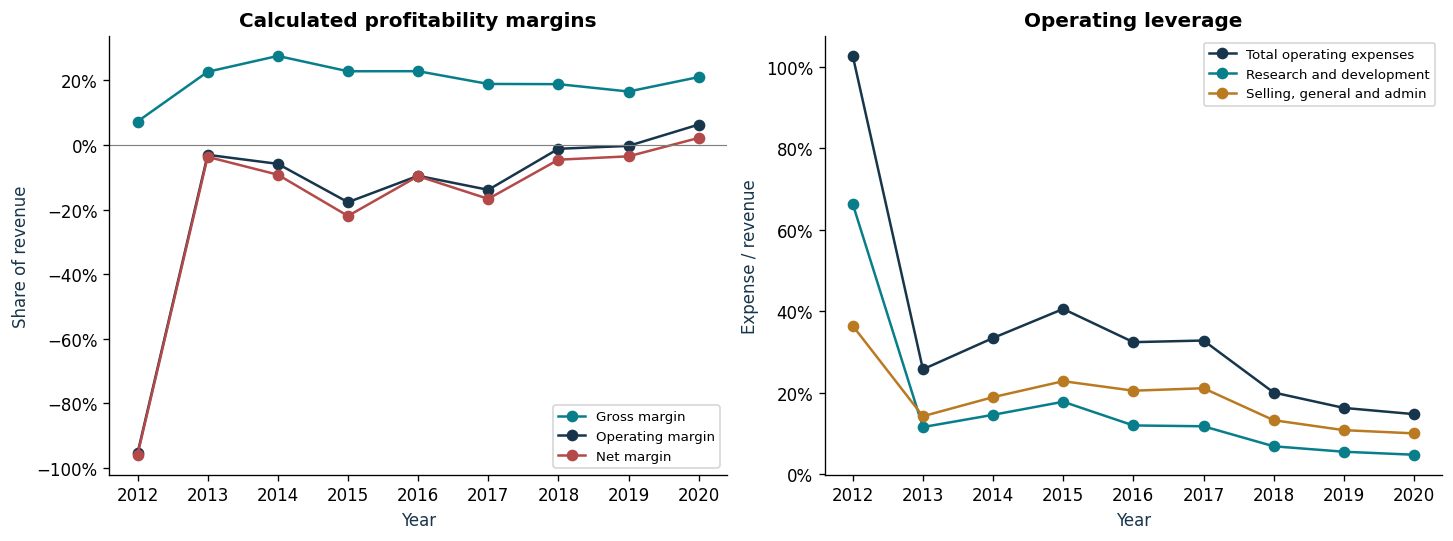

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained')
for col, label, color in [('gross_margin_pct', 'Gross margin', TEAL),
                          ('operating_margin_pct', 'Operating margin', NAVY),
                          ('net_margin_pct', 'Net margin', RED)]:
    axes[0].plot(historical.index, historical[col], marker='o', label=label, color=color)
axes[0].axhline(0, color='grey', linewidth=.7)
axes[0].yaxis.set_major_formatter(PercentFormatter(100))
axes[0].set(title='Calculated profitability margins', xlabel='Year', ylabel='Share of revenue')
axes[0].legend(fontsize=8)

for col, label, color in [('opex_to_revenue_pct', 'Total operating expenses', NAVY),
                          ('rnd_to_revenue_pct', 'Research and development', TEAL),
                          ('sga_to_revenue_pct', 'Selling, general and admin', AMBER)]:
    axes[1].plot(historical.index, historical[col], marker='o', label=label, color=color)
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
axes[1].set(title='Operating leverage', xlabel='Year', ylabel='Expense / revenue')
axes[1].legend(fontsize=8)
show_figure('margins_and_operating_leverage', fig)

## 3. Cash flow, liquidity and regulatory credits

Free cash flow here means **operating cash flow minus capital expenditure**.
Cash balances are a liquidity indicator; they do not by themselves establish a guaranteed share-price floor.

2020 net cash under the supplied debt definition: $7,696M


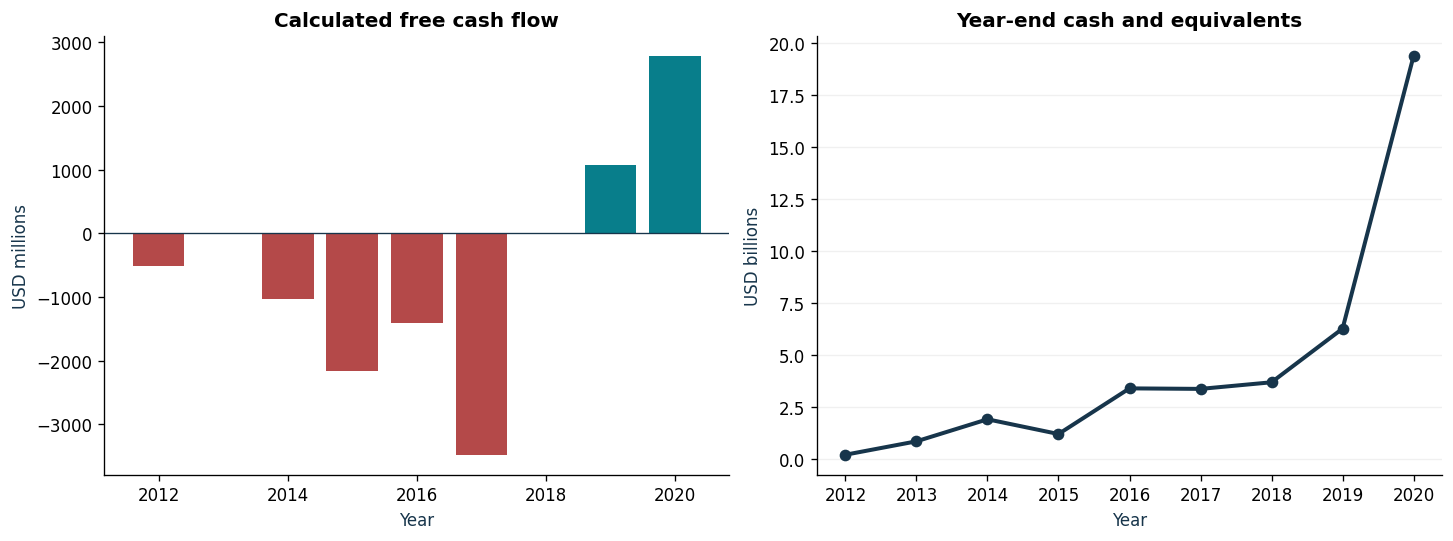

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained')
fcf = historical['free_cash_flow']
axes[0].bar(historical.index, fcf, color=[TEAL if value >= 0 else RED for value in fcf])
axes[0].axhline(0, color=NAVY, linewidth=.8)
axes[0].set(title='Calculated free cash flow', xlabel='Year', ylabel='USD millions')
axes[1].plot(historical.index, historical['cash_and_equivalents'] / 1000,
             marker='o', linewidth=2.4, color=NAVY)
axes[1].set(title='Year-end cash and equivalents', xlabel='Year', ylabel='USD billions')
axes[1].grid(axis='y', alpha=.18)
show_figure('cash_flow_and_liquidity', fig)

cash_2020 = historical.loc[2020, 'cash_and_equivalents']
reported_debt_2020 = 11688.0  # USD M; supplied report, not a live balance.
print(f'2020 net cash under the supplied debt definition: ${cash_2020 - reported_debt_2020:,.0f}M')

### Regulatory-credit contribution

The following is a simple **operating-income adjustment**: reported EBIT minus regulatory-credit revenue.
It holds all costs constant. It is not a restated GAAP measure and does not model taxes or business responses.
Subtracting pre-tax credit revenue directly from net income would mix pre-tax and after-tax measures.

**Regulatory-credit adjustment (USD millions, except margin)**

,revenue,regulatory_credits,operating_income,EBIT_less_credit_revenue,Revenue_less_credits,Adjusted_operating_margin_pct
year,,,,,,
2016,"7,000.13",302.30,-667.35,-969.65,"6,697.83",-14.48
2017,"11,758.75",360.30,"-1,632.08","-1,992.38","11,398.45",-17.48
2018,"21,461.27",418.60,-251.73,-670.33,"21,042.67",-3.19
2019,"24,578.00",594.00,-69.00,-663.00,"23,984.00",-2.76
2020,"31,536.00","1,580.00","1,994.00",414.00,"29,956.00",1.38


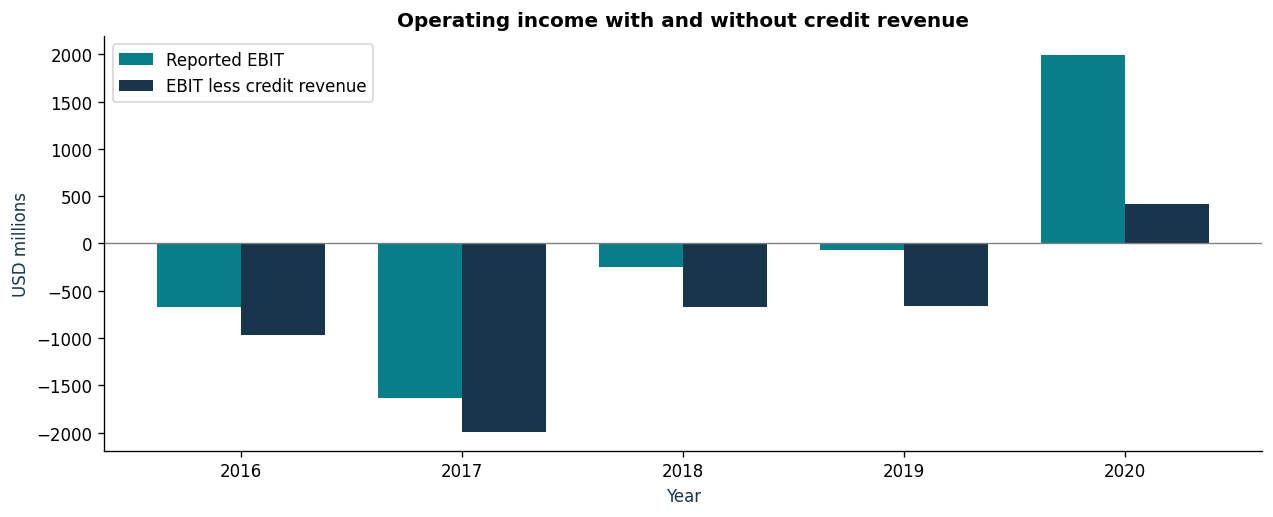

In [7]:
credit_analysis = historical.loc[2016:2020, ['revenue', 'regulatory_credits', 'operating_income']].copy()
credit_analysis['EBIT_less_credit_revenue'] = credit_analysis['operating_income'] - credit_analysis['regulatory_credits']
credit_analysis['Revenue_less_credits'] = credit_analysis['revenue'] - credit_analysis['regulatory_credits']
credit_analysis['Adjusted_operating_margin_pct'] = (
    credit_analysis['EBIT_less_credit_revenue'] / credit_analysis['Revenue_less_credits'] * 100
)
show_table(credit_analysis, 'Regulatory-credit adjustment (USD millions, except margin)')

fig, ax = plt.subplots(figsize=(10.5, 4.2), layout='constrained')
x = np.arange(len(credit_analysis))
ax.bar(x - .19, credit_analysis['operating_income'], width=.38, color=TEAL, label='Reported EBIT')
ax.bar(x + .19, credit_analysis['EBIT_less_credit_revenue'], width=.38, color=NAVY, label='EBIT less credit revenue')
ax.axhline(0, color='grey', linewidth=.8)
ax.set_xticks(x, credit_analysis.index.astype(str))
ax.set(title='Operating income with and without credit revenue', xlabel='Year', ylabel='USD millions')
ax.legend()
show_figure('regulatory_credit_adjustment', fig)

## 4. Peer comparison: source report's December 2020 snapshot

The figures below are reproduced from the report, including its peer definitions and valuation dates.
Fiscal periods, accounting treatment and enterprise-value definitions should be standardized before
using this table for a fresh comparable-company valuation. Missing ratios remain missing.

**Supplied 2020 peer data**

,Ticker,Market_cap_USD_M,Revenue_USD_M,EBITDA_USD_M,Net_margin_pct,EV_to_revenue,EV_to_EBITDA,PE
Company,,,,,,,,
Tesla,TSLA,"668,900.00","31,536.00","4,270.00",2.19,21.50,157.20,"1,102.00"
Toyota,TM,"215,200.00","249,500.00","29,400.00",7.10,1.40,9.20,10.50
Volkswagen,VOW3,"102,400.00","254,100.00","24,800.00",4.10,1.10,8.90,11.20
General Motors,GM,"59,400.00","122,485.00","14,100.00",5.25,1.20,13.30,12.10
Ford,F,"34,900.00","127,144.00","7,200.00",-1.00,1.20,36.90,—
NIO,NIO,"75,200.00","2,492.00",-780.00,-33.10,29.70,—,—


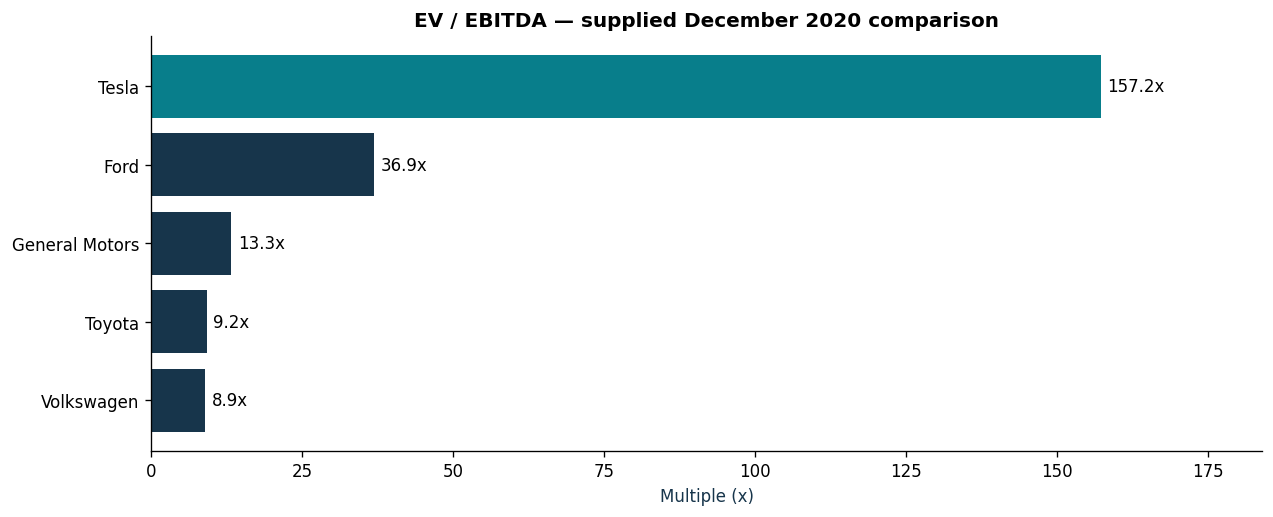

In [8]:
PEER_ROWS = [['Tesla', 'TSLA', '668,900', '31,536', '4,270', '2.19%', '21.5x', '157.2x', '1,102.0x'], ['Toyota', 'TM', '215,200', '249,500', '29,400', '7.10%', '1.4x', '9.2x', '10.5x'], ['Volkswagen', 'VOW3', '102,400', '254,100', '24,800', '4.10%', '1.1x', '8.9x', '11.2x'], ['General Motors', 'GM', '59,400', '122,485', '14,100', '5.25%', '1.2x', '13.3x', '12.1x'], ['Ford', 'F', '34,900', '127,144', '7,200', '-1.00%', '1.2x', '36.9x', 'N/A'], ['NIO', 'NIO', '75,200', '2,492', '(780)', '-33.10%', '29.7x', 'N/A', 'N/A']]
peers = pd.DataFrame(PEER_ROWS, columns=['Company', 'Ticker', 'Market_cap_USD_M', 'Revenue_USD_M',
                                       'EBITDA_USD_M', 'Net_margin_pct', 'EV_to_revenue', 'EV_to_EBITDA', 'PE'])
def parse_number(value):
    if value == 'N/A':
        return np.nan
    value = str(value).replace(',', '').replace('%', '').replace('x', '')
    return -float(value[1:-1]) if value.startswith('(') else float(value)

for col in peers.columns[2:]:
    peers[col] = peers[col].map(parse_number)
show_table(peers.set_index('Company'), 'Supplied 2020 peer data')

plot_peers = peers.dropna(subset=['EV_to_EBITDA']).sort_values('EV_to_EBITDA')
fig, ax = plt.subplots(figsize=(10.5, 4.2), layout='constrained')
bars = ax.barh(plot_peers['Company'], plot_peers['EV_to_EBITDA'],
               color=[TEAL if ticker == 'TSLA' else NAVY for ticker in plot_peers['Ticker']])
ax.bar_label(bars, labels=[f'{v:.1f}x' for v in plot_peers['EV_to_EBITDA']], padding=4)
ax.set(title='EV / EBITDA — supplied December 2020 comparison', xlabel='Multiple (x)')
ax.set_xlim(0, plot_peers['EV_to_EBITDA'].max() * 1.17)
show_figure('peer_ev_ebitda', fig)

## 5. Editable DCF assumptions

All forecast years are relative **Year 1–Year 5** because the source does not define a consistent
calendar-year valuation date for the forward model.

The supplied report contains two different CapEx interpretations:

| Interpretation | Year 1 | Year 2 | Year 3 | Year 4 | Year 5 |
|---|---:|---:|---:|---:|---:|
| Rates implied by its forecast amounts | 7.50% | 7.50% | 7.25% | 7.00% | 6.75% |
| Constant rate stated in its row label and earlier script | 7.50% | 7.50% | 7.50% | 7.50% | 7.50% |

The default baseline follows the **rates implied by the report's numeric forecast rows**.
A separate flat-CapEx case shows the other interpretation. Year 0 revenue is inferred from the
stated Year 1 revenue and growth rate; this also makes the first working-capital change reproducible.

The reported WACC is 11.45%. Its CAPM inputs imply 11.42845%, so the two inputs are shown separately.
`USE_CAPM_WACC = False` preserves the report's chosen 11.45% discount rate.

In [9]:
# Change these inputs to explore another scenario.
USE_CAPM_WACC = False
capital_inputs = {
    'risk_free_rate': 0.0425,
    'beta': 1.45,
    'equity_risk_premium': 0.05,
    'pretax_cost_of_debt': 0.055,
    'tax_rate': 0.21,
    'equity_weight': 0.99,
    'debt_weight': 0.01,
    'reported_wacc': 0.1145,
    'cash_and_investments': 33650.0,  # USD M; forward-model assumption
    'debt': 5750.0,                   # USD M; forward-model assumption
    'diluted_shares': 3180.0,          # Million shares
}
cost_of_equity = capital_inputs['risk_free_rate'] + capital_inputs['beta'] * capital_inputs['equity_risk_premium']
capm_wacc = (capital_inputs['equity_weight'] * cost_of_equity +
             capital_inputs['debt_weight'] * capital_inputs['pretax_cost_of_debt'] *
             (1 - capital_inputs['tax_rate']))
chosen_wacc = capm_wacc if USE_CAPM_WACC else capital_inputs['reported_wacc']

common = {
    'tax_rate': capital_inputs['tax_rate'],
    'da_rate': 0.048,
    'nwc_rate_of_revenue_change': 0.03,
    'wacc': chosen_wacc,
    'cash': capital_inputs['cash_and_investments'],
    'debt': capital_inputs['debt'],
    'shares': capital_inputs['diluted_shares'],
    'mid_year': True,
}
baseline = {
    **common,
    'name': 'Baseline: implied CapEx taper',
    'base_year_revenue': 110000.0 / 1.14,
    'growth_rates': [0.14, 0.15, 0.14, 0.13, 0.12],
    'ebit_margins': [0.095, 0.105, 0.115, 0.125, 0.135],
    'capex_rates': [0.075, 0.075, 0.0725, 0.0700, 0.0675],
    'terminal_growth': 0.025,
}
bear = {
    **common,
    'name': 'Bear case',
    'base_year_revenue': 100000.0 / 1.04,
    'growth_rates': [0.04, 0.05, 0.04, 0.03, 0.02],
    'ebit_margins': [0.06] * 5,
    'capex_rates': [0.065] * 5,
    'terminal_growth': 0.02,
}
flat_capex = deepcopy(baseline)
flat_capex['name'] = 'Baseline: flat 7.5% CapEx'
flat_capex['capex_rates'] = [0.075] * 5

print(f'Cost of equity: {cost_of_equity:.4%}')
print(f'WACC calculated from CAPM inputs: {capm_wacc:.5%}')
print(f'WACC used in the DCF: {chosen_wacc:.4%}')
assumption_table = pd.DataFrame({
    'Baseline growth (%)': np.array(baseline['growth_rates']) * 100,
    'Baseline EBIT margin (%)': np.array(baseline['ebit_margins']) * 100,
    'Baseline CapEx / revenue (%)': np.array(baseline['capex_rates']) * 100,
    'Bear growth (%)': np.array(bear['growth_rates']) * 100,
    'Bear EBIT margin (%)': np.array(bear['ebit_margins']) * 100,
    'Bear CapEx / revenue (%)': np.array(bear['capex_rates']) * 100,
}, index=pd.Index(range(1, 6), name='Forecast year'))
show_table(assumption_table, 'Editable forecast assumptions')

Cost of equity: 11.5000%
WACC calculated from CAPM inputs: 11.42845%
WACC used in the DCF: 11.4500%


**Editable forecast assumptions**

,Baseline growth (%),Baseline EBIT margin (%),Baseline CapEx / revenue (%),Bear growth (%),Bear EBIT margin (%),Bear CapEx / revenue (%)
Forecast year,,,,,,
1,14.00,9.50,7.50,4.00,6.00,6.50
2,15.00,10.50,7.50,5.00,6.00,6.50
3,14.00,11.50,7.25,4.00,6.00,6.50
4,13.00,12.50,7.00,3.00,6.00,6.50
5,12.00,13.50,6.75,2.00,6.00,6.50


### Forecast engine and valuation formulas

\[
\mathrm{UFCF}_t = \mathrm{EBIT}_t - \mathrm{CashTaxes}_t + \mathrm{D\&A}_t
                  - \mathrm{CapEx}_t - \Delta\mathrm{NWC}_t
\]

\[
PV(\mathrm{UFCF}_t) = \frac{\mathrm{UFCF}_t}{(1+WACC)^{t-0.5}},\qquad
TV_n = \frac{\mathrm{UFCF}_n(1+g)}{WACC-g}
\]

\[
\mathrm{EquityValue} = \sum PV(\mathrm{UFCF}_t) + \frac{TV_n}{(1+WACC)^n}
                       + \mathrm{Cash} - \mathrm{Debt}
\]

Explicit cash flows use the report's mid-year convention; terminal value is discounted from the end
of Year 5. Terminal cash flow is Year 5 UFCF grown by `g`, consistently with the perpetuity formula.
Cash taxes apply only to positive EBIT, without an immediate cash benefit on a loss. D&A and CapEx
are percentages of revenue; working capital is a percentage of the **change** in revenue.

In [10]:
def run_dcf(assumptions):
    """Return a forecast DataFrame and valuation Series, all amounts in USD M."""
    a = assumptions
    growth = np.asarray(a['growth_rates'], dtype=float)
    margins = np.asarray(a['ebit_margins'], dtype=float)
    capex_rates = np.asarray(a['capex_rates'], dtype=float)
    n = len(growth)
    if n == 0 or len(margins) != n or len(capex_rates) != n:
        raise ValueError('Growth, margin and CapEx arrays must have the same nonzero length.')
    if not np.isfinite(np.concatenate([growth, margins, capex_rates])).all():
        raise ValueError('Forecast inputs must be finite numbers.')
    if a['base_year_revenue'] <= 0 or np.any(growth <= -1):
        raise ValueError('Revenue must be positive and growth must be greater than -100%.')
    if a['wacc'] <= a['terminal_growth'] or a['wacc'] <= -1 or a['terminal_growth'] <= -1:
        raise ValueError('WACC must exceed terminal growth; both must be greater than -100%.')
    if a['shares'] <= 0 or not 0 <= a['tax_rate'] <= 1:
        raise ValueError('Shares must be positive and the tax rate must be between zero and one.')
    if np.any(capex_rates < 0) or a['da_rate'] < 0 or a['nwc_rate_of_revenue_change'] < 0:
        raise ValueError('CapEx, D&A and working-capital ratios must be nonnegative.')

    years = np.arange(1, n + 1)
    revenue = a['base_year_revenue'] * np.cumprod(1 + growth)
    prior_revenue = np.r_[a['base_year_revenue'], revenue[:-1]]
    ebit = revenue * margins
    taxes = np.maximum(ebit, 0) * a['tax_rate']
    nopat = ebit - taxes
    da = revenue * a['da_rate']
    capex = revenue * capex_rates
    delta_nwc = (revenue - prior_revenue) * a['nwc_rate_of_revenue_change']
    ufcf = nopat + da - capex - delta_nwc
    discount_period = years - 0.5 if a['mid_year'] else years.astype(float)
    discount_factor = (1 + a['wacc']) ** (-discount_period)
    pv_ufcf = ufcf * discount_factor

    terminal_cash_flow = ufcf[-1] * (1 + a['terminal_growth'])
    terminal_value = terminal_cash_flow / (a['wacc'] - a['terminal_growth'])
    pv_terminal = terminal_value / (1 + a['wacc']) ** n
    enterprise_value = pv_ufcf.sum() + pv_terminal
    net_cash = a['cash'] - a['debt']
    equity_value = enterprise_value + net_cash

    forecast = pd.DataFrame({
        'Revenue': revenue, 'Growth_pct': growth * 100,
        'EBIT': ebit, 'EBIT_margin_pct': margins * 100,
        'Cash_taxes': taxes, 'NOPAT': nopat,
        'DA': da, 'CapEx': capex, 'CapEx_rate_pct': capex_rates * 100,
        'Delta_NWC': delta_nwc, 'UFCF': ufcf,
        'Discount_period': discount_period, 'Discount_factor': discount_factor,
        'PV_UFCF': pv_ufcf,
    }, index=pd.Index(years, name='Year'))
    valuation = pd.Series({
        'PV_explicit_UFCF': pv_ufcf.sum(),
        'Terminal_cash_flow': terminal_cash_flow,
        'Terminal_value': terminal_value,
        'PV_terminal_value': pv_terminal,
        'Enterprise_value': enterprise_value,
        'Net_cash': net_cash,
        'Equity_value': equity_value,
        'Diluted_shares': a['shares'],
        'Value_per_share': equity_value / a['shares'],
        'Terminal_share_of_EV_pct': pv_terminal / enterprise_value * 100 if enterprise_value else np.nan,
    }, name=a['name'])
    return forecast, valuation

base_forecast, base_valuation = run_dcf(baseline)
bear_forecast, bear_valuation = run_dcf(bear)
flat_forecast, flat_valuation = run_dcf(flat_capex)
show_table(base_forecast.T, 'Baseline forecast — report-implied CapEx taper')
show_table(bear_forecast.T, 'Bear-case forecast')
valuations = pd.concat([base_valuation, bear_valuation, flat_valuation], axis=1)
show_table(valuations, 'Calculated valuation bridge (USD M, except shares and ratios)')

**Baseline forecast — report-implied CapEx taper**

Year,1,2,3,4,5
Revenue,"110,000.00","126,500.00","144,210.00","162,957.30","182,512.18"
Growth_pct,14.00,15.00,14.00,13.00,12.00
EBIT,"10,450.00","13,282.50","16,584.15","20,369.66","24,639.14"
EBIT_margin_pct,9.50,10.50,11.50,12.50,13.50
Cash_taxes,"2,194.50","2,789.33","3,482.67","4,277.63","5,174.22"
NOPAT,"8,255.50","10,493.18","13,101.48","16,092.03","19,464.92"
DA,"5,280.00","6,072.00","6,922.08","7,821.95","8,760.58"
CapEx,"8,250.00","9,487.50","10,455.23","11,407.01","12,319.57"
CapEx_rate_pct,7.50,7.50,7.25,7.00,6.75
Delta_NWC,405.26,495.00,531.30,562.42,586.65


**Bear-case forecast**

Year,1,2,3,4,5
Revenue,"100,000.00","105,000.00","109,200.00","112,476.00","114,725.52"
Growth_pct,4.00,5.00,4.00,3.00,2.00
EBIT,"6,000.00","6,300.00","6,552.00","6,748.56","6,883.53"
EBIT_margin_pct,6.00,6.00,6.00,6.00,6.00
Cash_taxes,"1,260.00","1,323.00","1,375.92","1,417.20","1,445.54"
NOPAT,"4,740.00","4,977.00","5,176.08","5,331.36","5,437.99"
DA,"4,800.00","5,040.00","5,241.60","5,398.85","5,506.82"
CapEx,"6,500.00","6,825.00","7,098.00","7,310.94","7,457.16"
CapEx_rate_pct,6.50,6.50,6.50,6.50,6.50
Delta_NWC,115.38,150.00,126.00,98.28,67.49


**Calculated valuation bridge (USD M, except shares and ratios)**

,Baseline: implied CapEx taper,Bear case,Baseline: flat 7.5% CapEx
PV_explicit_UFCF,"34,687.79","12,163.56","33,014.92"
Terminal_cash_flow,"15,702.27","3,488.57","14,299.21"
Terminal_value,"175,444.38","36,916.12","159,767.71"
PV_terminal_value,"102,032.63","21,469.19","92,915.60"
Enterprise_value,"136,720.43","33,632.75","125,930.52"
Net_cash,"27,900.00","27,900.00","27,900.00"
Equity_value,"164,620.43","61,532.75","153,830.52"
Diluted_shares,"3,180.00","3,180.00","3,180.00"
Value_per_share,51.77,19.35,48.37
Terminal_share_of_EV_pct,74.63,63.83,73.78


### Reconcile the notebook with the PDF

Using the report-implied CapEx taper should reproduce the baseline's rounded share value closely.
Small differences come from recalculating discount factors and the first working-capital change
without intermediate rounding. The flat 7.5% CapEx interpretation produces a materially different
result, so it remains a separate scenario rather than silently replacing the source.

**Report vs. calculated model**

,PDF value per share (USD),Notebook value per share (USD),Difference (USD)
Baseline: implied CapEx taper,51.7700,51.7674,-0.0026
Bear case,19.3500,19.3499,-0.0001
Baseline: flat 7.5% CapEx,—,48.3744,—


**CapEx reconciliation**

,Report CapEx (USD M),Rate implied by report (%),Calculated tapered CapEx (USD M),Calculated flat CapEx (USD M)
Year,,,,
1,"8,250.000",7.500,"8,250.000","8,250.000"
2,"9,487.500",7.500,"9,487.500","9,487.500"
3,"10,455.230",7.250,"10,455.225","10,815.750"
4,"11,407.010",7.000,"11,407.011","12,221.798"
5,"12,319.570",6.750,"12,319.572","13,688.413"


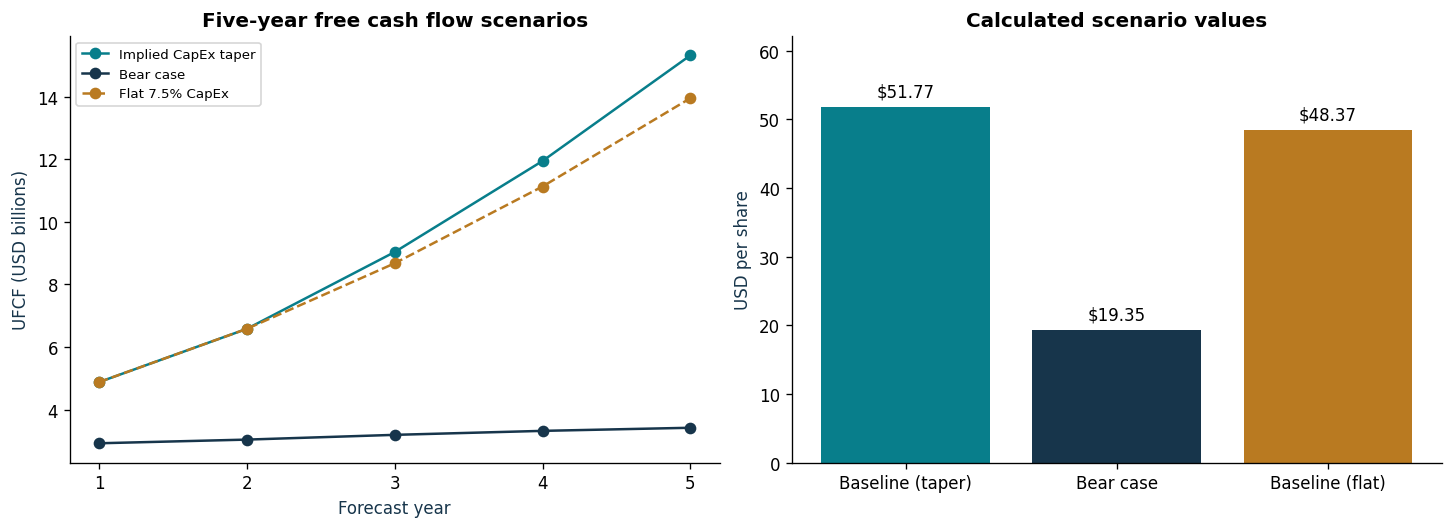

In [11]:
source_comparison = pd.DataFrame({
    'PDF value per share (USD)': [51.77, 19.35, np.nan],
    'Notebook value per share (USD)': [base_valuation['Value_per_share'],
                                       bear_valuation['Value_per_share'],
                                       flat_valuation['Value_per_share']],
}, index=['Baseline: implied CapEx taper', 'Bear case', 'Baseline: flat 7.5% CapEx'])
source_comparison['Difference (USD)'] = (source_comparison['Notebook value per share (USD)'] -
                                       source_comparison['PDF value per share (USD)'])
show_table(source_comparison, 'Report vs. calculated model', precision=4)

reported_capex = np.array([8250.00, 9487.50, 10455.23, 11407.01, 12319.57])
capex_reconciliation = pd.DataFrame({
    'Report CapEx (USD M)': reported_capex,
    'Rate implied by report (%)': reported_capex / base_forecast['Revenue'].to_numpy() * 100,
    'Calculated tapered CapEx (USD M)': base_forecast['CapEx'],
    'Calculated flat CapEx (USD M)': flat_forecast['CapEx'],
}, index=base_forecast.index)
show_table(capex_reconciliation, 'CapEx reconciliation', precision=3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
for frame, label, color, style in [(base_forecast, 'Implied CapEx taper', TEAL, '-'),
                                    (bear_forecast, 'Bear case', NAVY, '-'),
                                    (flat_forecast, 'Flat 7.5% CapEx', AMBER, '--')]:
    axes[0].plot(frame.index, frame['UFCF'] / 1000, color=color, linestyle=style,
                 marker='o', label=label)
axes[0].set(title='Five-year free cash flow scenarios', xlabel='Forecast year', ylabel='UFCF (USD billions)')
axes[0].set_xticks(range(1, 6))
axes[0].legend(fontsize=8)
prices = [base_valuation['Value_per_share'], bear_valuation['Value_per_share'], flat_valuation['Value_per_share']]
bars = axes[1].bar(['Baseline (taper)', 'Bear case', 'Baseline (flat)'], prices, color=[TEAL, NAVY, AMBER])
axes[1].bar_label(bars, labels=[f'${value:.2f}' for value in prices], padding=4)
axes[1].set(title='Calculated scenario values', ylabel='USD per share')
axes[1].set_ylim(0, max(prices) * 1.2)
show_figure('dcf_scenarios', fig)

## 6. WACC and terminal-growth sensitivity

This grid changes only the discount rate and terminal growth rate. It holds the baseline operating
forecast, cash, debt and share count constant. Cells with terminal growth at or above WACC are invalid.

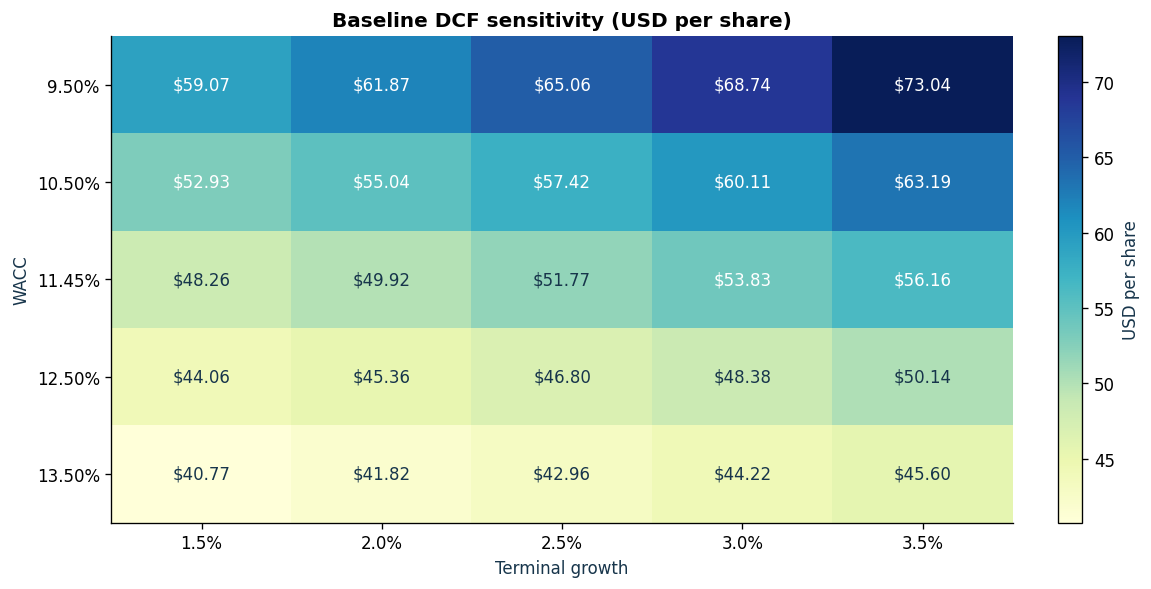

In [12]:
wacc_grid = [0.095, 0.105, 0.1145, 0.125, 0.135]
terminal_growth_grid = [0.015, 0.020, 0.025, 0.030, 0.035]
sensitivity = pd.DataFrame(index=wacc_grid, columns=terminal_growth_grid, dtype=float)
for wacc in wacc_grid:
    for growth in terminal_growth_grid:
        scenario = deepcopy(baseline)
        scenario.update(wacc=wacc, terminal_growth=growth)
        sensitivity.loc[wacc, growth] = (run_dcf(scenario)[1]['Value_per_share']
                                         if wacc > growth else np.nan)
sensitivity.index.name = 'WACC'
sensitivity.columns.name = 'Terminal growth'

fig, ax = plt.subplots(figsize=(9.5, 4.8), layout='constrained')
im = ax.imshow(sensitivity.to_numpy(), cmap='YlGnBu', aspect='auto')
ax.set_xticks(range(len(terminal_growth_grid)), [f'{v:.1%}' for v in terminal_growth_grid])
ax.set_yticks(range(len(wacc_grid)), [f'{v:.2%}' for v in wacc_grid])
midpoint = np.nanmedian(sensitivity.to_numpy())
for i in range(len(wacc_grid)):
    for j in range(len(terminal_growth_grid)):
        value = sensitivity.iloc[i, j]
        ax.text(j, i, f'${value:.2f}', ha='center', va='center',
                color='white' if value > midpoint else NAVY)
ax.set(title='Baseline DCF sensitivity (USD per share)', xlabel='Terminal growth', ylabel='WACC')
fig.colorbar(im, ax=ax, label='USD per share')
show_figure('wacc_terminal_growth_sensitivity', fig)

## 7. Autonomy and FSD monetization scenario

These are **illustrative inputs from the report**, not observed subscriptions or current prices.
The software value uses a supplied **10.44× enterprise-value / Year 5 UFCF multiplier**. It is not a
separately forecast software DCF. The retail and commercial prices below are scenario inputs.

Adding this software value to the baseline assumes the modeled cash flows are fully incremental.
A full sum-of-the-parts model would first remove any software earnings already included in the baseline
to prevent double counting. The following grid is an exploratory sensitivity, not that full reconciliation.

Additional enterprise value to reach the assumed $200 target: $471.38B
Required Year 5 software UFCF under the assumed multiplier: $45.15B
$99/month at 100% adoption under these assumptions: $88.27/share total


**Baseline plus assumed incremental software value (USD per share)**

Adoption rate,0.150000,0.300000,0.500000,0.700000,0.900000
Monthly ARPU (USD),,,,,
99.000000,57.24,62.72,70.02,77.32,84.62
200.000000,62.83,73.89,88.64,103.39,118.14
350.000000,71.13,90.49,116.30,142.11,167.92
500.000000,79.42,107.08,143.95,180.83,217.70
750.000000,93.25,134.74,190.05,245.36,300.67
1000.000000,107.08,162.39,236.14,309.89,383.64


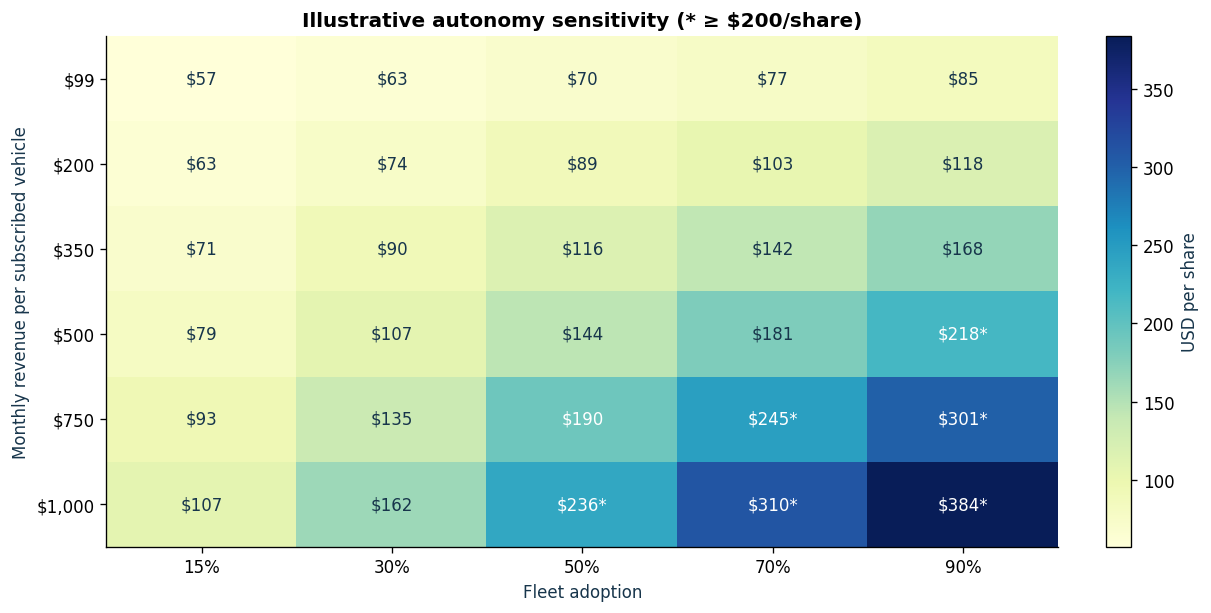

In [13]:
software_inputs = {
    'active_fleet_millions': 18.0,
    'cash_flow_conversion': 0.52,
    'ev_to_year5_ufcf': 10.44,
    'target_price': 200.0,
}
monthly_arpu = np.array([99, 200, 350, 500, 750, 1000], dtype=float)
adoption_rates = np.array([0.15, 0.30, 0.50, 0.70, 0.90])
# A fleet measured in millions times USD per vehicle yields revenue in USD millions.
software_revenue = software_inputs['active_fleet_millions'] * monthly_arpu[:, None] * 12 * adoption_rates[None, :]
software_ufcf = software_revenue * software_inputs['cash_flow_conversion']
software_ev = software_ufcf * software_inputs['ev_to_year5_ufcf']
total_price = base_valuation['Value_per_share'] + software_ev / baseline['shares']
fsd_sensitivity = pd.DataFrame(total_price, index=monthly_arpu, columns=adoption_rates)
fsd_sensitivity.index.name = 'Monthly ARPU (USD)'
fsd_sensitivity.columns.name = 'Adoption rate'
show_table(fsd_sensitivity, 'Baseline plus assumed incremental software value (USD per share)')

incremental_ev_needed = max(0, (software_inputs['target_price'] - base_valuation['Value_per_share']) * baseline['shares'])
required_software_ufcf = incremental_ev_needed / software_inputs['ev_to_year5_ufcf']
retail_ceiling_revenue = software_inputs['active_fleet_millions'] * 99 * 12
retail_ceiling_price = (base_valuation['Value_per_share'] + retail_ceiling_revenue *
                        software_inputs['cash_flow_conversion'] * software_inputs['ev_to_year5_ufcf'] / baseline['shares'])
print(f'Additional enterprise value to reach the assumed $200 target: ${incremental_ev_needed / 1000:,.2f}B')
print(f'Required Year 5 software UFCF under the assumed multiplier: ${required_software_ufcf / 1000:,.2f}B')
print(f'$99/month at 100% adoption under these assumptions: ${retail_ceiling_price:.2f}/share total')

fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
im = ax.imshow(total_price, cmap='YlGnBu', aspect='auto')
ax.set_xticks(range(len(adoption_rates)), [f'{v:.0%}' for v in adoption_rates])
ax.set_yticks(range(len(monthly_arpu)), [f'${v:,.0f}' for v in monthly_arpu])
for i in range(len(monthly_arpu)):
    for j in range(len(adoption_rates)):
        value = total_price[i, j]
        ax.text(j, i, f'${value:.0f}' + ('*' if value >= software_inputs['target_price'] else ''),
                ha='center', va='center', color='white' if value > 190 else NAVY)
ax.set(title='Illustrative autonomy sensitivity (* ≥ $200/share)',
       xlabel='Fleet adoption', ylabel='Monthly revenue per subscribed vehicle')
fig.colorbar(im, ax=ax, label='USD per share')
show_figure('fsd_adoption_sensitivity', fig)

## 8. Pie charts: compute budget and bear-case equity value

The first chart reproduces the report's budget percentages, which total 100%.
The second uses the notebook's recalculated bear-case enterprise value and assumed net cash.
It updates when the DCF assumptions change. If a component becomes negative, a bar chart replaces
that pie because a negative component is not a meaningful share of a pie.

The budget percentages are supplied assumptions, not percentages recalculated from the range midpoints.


**Illustrative infrastructure allocation from the report**

,Share_pct,Annual_low_USD_M,Annual_high_USD_M
Subsystem,,,
Accelerators (GPU / Dojo),58.50,"2,200","3,800"
Power infrastructure & shell,13.80,500,900
Liquid cooling,12.30,400,800
NVMe storage,8.50,250,550
Optical interconnect,6.90,150,450


**Recalculated bear-case equity value composition**

,USD millions,USD per share,Share_pct
Operating enterprise value,"33,632.75",10.58,54.66
Net cash,"27,900.00",8.77,45.34


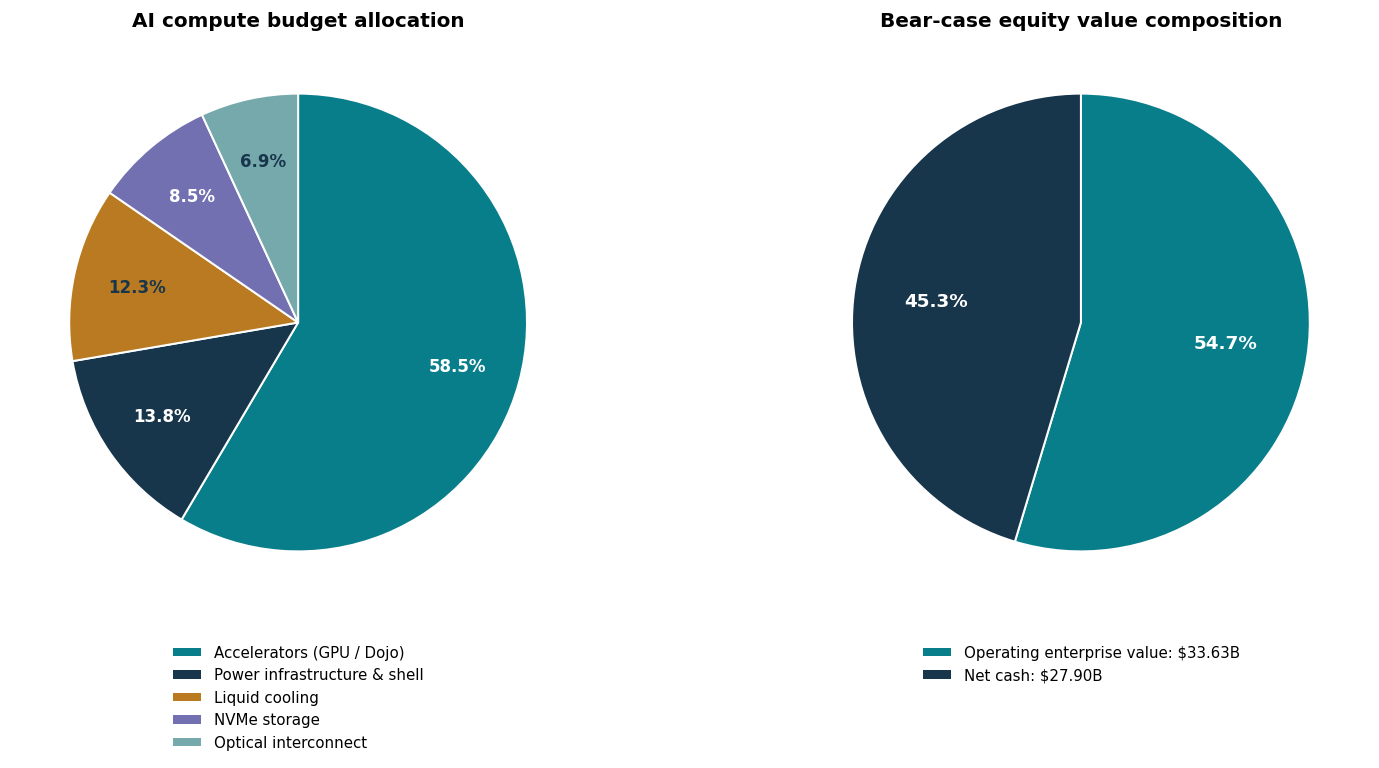

In [14]:
compute_budget = pd.DataFrame({
    'Subsystem': ['Accelerators (GPU / Dojo)', 'Power infrastructure & shell',
                  'Liquid cooling', 'NVMe storage', 'Optical interconnect'],
    'Share_pct': [58.5, 13.8, 12.3, 8.5, 6.9],
    'Annual_low_USD_M': [2200, 500, 400, 250, 150],
    'Annual_high_USD_M': [3800, 900, 800, 550, 450],
})
assert np.isclose(compute_budget['Share_pct'].sum(), 100)
show_table(compute_budget.set_index('Subsystem'), 'Illustrative infrastructure allocation from the report')
print('The budget percentages are supplied assumptions, not percentages recalculated from the range midpoints.')

equity_components = pd.Series({
    'Operating enterprise value': bear_valuation['Enterprise_value'],
    'Net cash': bear_valuation['Net_cash'],
})
equity_breakdown = pd.DataFrame({
    'USD millions': equity_components,
    'USD per share': equity_components / bear['shares'],
    'Share_pct': equity_components / equity_components.sum() * 100,
})
show_table(equity_breakdown, 'Recalculated bear-case equity value composition')

fig, axes = plt.subplots(1, 2, figsize=(13, 6.3), layout='constrained')
wedges, _, pct_text = axes[0].pie(
    compute_budget['Share_pct'], colors=PALETTE, startangle=90, counterclock=False,
    autopct='%1.1f%%', pctdistance=.72,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.2},
    textprops={'color': 'white', 'fontsize': 10, 'fontweight': 'bold'},
)
for i in [2, 4]:
    pct_text[i].set_color(NAVY)
axes[0].set_title('AI compute budget allocation')
axes[0].legend(wedges, compute_budget['Subsystem'], loc='upper center',
               bbox_to_anchor=(.5, -.04), frameon=False, fontsize=9)

if equity_components.ge(0).all() and equity_components.sum() > 0:
    wedges, _, _ = axes[1].pie(
        equity_components, colors=[TEAL, NAVY], startangle=90, counterclock=False,
        autopct='%1.1f%%', pctdistance=.64,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.2},
        textprops={'color': 'white', 'fontsize': 11, 'fontweight': 'bold'},
    )
    labels = [f'{label}: ${value / 1000:,.2f}B' for label, value in equity_components.items()]
    axes[1].legend(wedges, labels, loc='upper center', bbox_to_anchor=(.5, -.04),
                   frameon=False, fontsize=9)
else:
    axes[1].bar(equity_components.index, equity_components / 1000, color=[TEAL, NAVY])
    axes[1].axhline(0, color='grey', linewidth=.8)
    axes[1].set_ylabel('USD billions')
axes[1].set_title('Bear-case equity value composition')
show_figure('compute_and_equity_pie_charts', fig)

## 9. Centralized compute unit economics

An allocation across the whole fleet differs from a cost per paying subscriber. Both are shown below.
Revenue minus allocated compute spend excludes engineering, connectivity, insurance, tax and other
costs, so it is **not a complete software profit margin**.

In [15]:
annual_compute_usd_m = 4500.0
active_fleet_millions = 18.0
paying_adoption = 0.30
monthly_subscription_usd = 99.0
robotaxi_fleet_millions = 2.0
annual_miles_per_robotaxi = 45000.0

annual_cost_per_fleet_vehicle = annual_compute_usd_m / active_fleet_millions
monthly_cost_per_fleet_vehicle = annual_cost_per_fleet_vehicle / 12
monthly_cost_per_subscriber = annual_compute_usd_m / (active_fleet_millions * paying_adoption) / 12
compute_cost_per_robotaxi_mile = annual_compute_usd_m / (robotaxi_fleet_millions * annual_miles_per_robotaxi)
compute_unit_economics = pd.Series({
    'Annual compute / fleet vehicle (USD)': annual_cost_per_fleet_vehicle,
    'Monthly compute / fleet vehicle (USD)': monthly_cost_per_fleet_vehicle,
    'Monthly compute / paying subscriber at 30% adoption (USD)': monthly_cost_per_subscriber,
    'Revenue less fleet-allocated monthly compute (USD)': monthly_subscription_usd - monthly_cost_per_fleet_vehicle,
    'Revenue less subscriber-allocated monthly compute (USD)': monthly_subscription_usd - monthly_cost_per_subscriber,
    'Compute / commercial robotaxi mile (USD)': compute_cost_per_robotaxi_mile,
}, name='Scenario calculation')
show_table(compute_unit_economics.to_frame(), 'Illustrative compute economics', precision=3)

workloads = pd.Series({'Perception and auto-labeling': 45.0,
                      'World models': 30.0, 'Foundation policy': 25.0}, name='Compute cycles (%)')
show_table(workloads.to_frame(), 'Workload allocation assumed in the source')

**Illustrative compute economics**

,Scenario calculation
Annual compute / fleet vehicle (USD),250.000
Monthly compute / fleet vehicle (USD),20.833
Monthly compute / paying subscriber at 30% adoption (USD),69.444
Revenue less fleet-allocated monthly compute (USD),78.167
Revenue less subscriber-allocated monthly compute (USD),29.556
Compute / commercial robotaxi mile (USD),0.050


**Workload allocation assumed in the source**

,Compute cycles (%)
Perception and auto-labeling,45.00
World models,30.00
Foundation policy,25.00


## 10. In-vehicle autonomy hardware costs

The table preserves the report's engineering and bill-of-materials estimates. These are **unverified
source estimates**, especially its next-generation AI5 claims. They should not be presented as confirmed
product specifications. The chart calculates midpoint costs and shows the full stated ranges.

In [ ]:
HARDWARE_ROWS = [['Foundry process', '14nm FinFET (Samsung)', '7nm / 5nm (Samsung / TSMC)', '3nm / 4nm (TSMC / Samsung)'], ['Transistor footprint', '~6 billion', '~15 billion', '~50+ billion'], ['SoC dies', 'Dual custom FSD SoCs', 'Dual larger custom SoCs', 'Dual multi-die CoWoS modules'], ['Raw AI inference', '~144 TOPS (INT8)', '~450 TOPS (INT8)', '~2,000-4,000 TOPS'], ['Memory', '8 × 2GB LPDDR4 (128-bit)', '16 × LPDDR5 / GDDR6', 'High-density LPDDR5X pools'], ['Power draw', '~72 W under load', '~120 W under load', '~600-800 W peak'], ['Cooling', 'Shared liquid-loop plate', 'Integrated liquid manifold', 'Dedicated high-flow cold plate'], ['Standalone computer cost', '$350-420', '$620-710', '$1,800-2,500'], ['Camera sensor suite', '8 × 1.2 MP AR0136', '8 × 5.0 MP Sony IMX', '8-10 ultra-high-res / coatings'], ['Optics & housings', '$180-220', '$280-340', '$350-420'], ['FAKRA / automotive wiring', '$90-120', '$120-150', '$150-180'], ['Redundant low-voltage wiring', '$50-70', '$60-80', '$80-110'], ['Total autonomy suite BOM', '$670-830', '$1,080-1,280', '$2,380-3,210']]
hardware_table = pd.DataFrame(HARDWARE_ROWS,
    columns=['Subsystem', 'AI3 / HW3 (source)', 'AI4 / HW4 (source)', 'AI5 / HW5 (source estimate)'])
display(hardware_table.set_index('Subsystem'))

hardware_costs = pd.DataFrame({
    'Generation': ['AI3 / HW3', 'AI4 / HW4', 'AI5 / HW5'],
    'Low_USD': [670, 1080, 2380],
    'High_USD': [830, 1280, 3210],
}).set_index('Generation')
hardware_costs['Midpoint_USD'] = (hardware_costs['Low_USD'] + hardware_costs['High_USD']) / 2
assumed_vehicle_cogs = 36000.0
hardware_costs['Share_of_assumed_vehicle_COGS_pct'] = hardware_costs['Midpoint_USD'] / assumed_vehicle_cogs * 100
show_table(hardware_costs, 'Autonomy suite cost estimates and implied manufacturing share')

fig, ax = plt.subplots(figsize=(10.5, 4.4), layout='constrained')
mid = hardware_costs['Midpoint_USD']
errors = np.vstack([mid - hardware_costs['Low_USD'], hardware_costs['High_USD'] - mid])
bars = ax.bar(hardware_costs.index, mid, yerr=errors, capsize=7, color=[NAVY, TEAL, AMBER])
for i, value in enumerate(mid):
    ax.text(i, hardware_costs['High_USD'].iloc[i] + 100, f'${value:,.0f} midpoint', ha='center')
ax.set(title='Autonomy hardware BOM — supplied cost ranges', ylabel='Cost per vehicle (USD)')
ax.set_ylim(0, hardware_costs['High_USD'].max() * 1.22)
show_figure('hardware_bom_ranges', fig)

## 11. Strategic context and retrospective research

The report links Tesla's expansion to its product rollout, direct distribution, charging infrastructure,
in-house vehicle architecture, factory investment and energy-storage business. These qualitative
themes can help explain the financial measures above, but the notebook does not estimate their
individual causal contributions.

### Historical strategy notes from the supplied report

| Theme | Connection to the analysis |
|---|---|
| Roadster, Model S/X, Model 3 and Model Y rollout | Revenue growth and manufacturing scale |
| Direct distribution and software-enabled customer relationships | Selling expense and service economics |
| Supercharger infrastructure and battery systems | Capital intensity and customer adoption |
| Shanghai and other factory investments | Capacity growth, CapEx and localization |
| Regulatory credits | Difference between reported EBIT and the simple ex-credit scenario |
| Energy storage and autonomy | Separate future business assumptions and execution risk |

The source's retrospective section describes several predictions as accurate. Its observation windows
and comparison definitions are incomplete, so the following are verification questions for further work:

- How much regulatory-credit revenue was recognized in each later fiscal year?
- Are energy-deployment observations annual results or interim run rates?
- Does a competitor-volume comparison refer to battery-electric vehicles or all plug-in vehicles?
- Which autonomy capability, market and approval date is being compared with the original forecast?

The source's post-2020 energy and autonomy statements are not treated as independently verified outcomes here.

## 12. Risk framework

The categories below are carried over from the report. Severity and likelihood are qualitative source
judgments, not statistically estimated probabilities. A scenario value that includes net cash is not a
guaranteed downside floor: cash balances, debt, future losses and the share count can all change.

In [17]:
RISK_ROWS = [['Hardware valuation downside', 'High / High', 'FSD willingness to pay stays at $99/month; auto gross margins below 12%.', '$27.9B net cash; $19.35/share scenario floor; growing Megapack cash flow.'], ['Autonomous execution delay', 'High / Medium', 'Edge-case safety failures; regulatory halts; multiple jurisdictions.', 'Fleet data engine; vision-only architecture; end-to-end network testing.'], ['Geopolitical / supply chain', 'Medium / High', 'Shanghai concentration; tariffs and local supply dependencies.', 'Regional Berlin and Texas facilities; localized supply chains.'], ['Key person risk', 'High / Medium', 'Executive attention divided across xAI, SpaceX, X/Corp and other ventures.', 'Incentives tied to operating targets and autonomy milestones.']]
risk_table = pd.DataFrame(RISK_ROWS, columns=['Risk', 'Source severity / likelihood',
                                            'Source exposure scenario', 'Source mitigation claim'])
display(risk_table.set_index('Risk'))

,Source severity / likelihood,Source exposure scenario,Source mitigation claim
Risk,,,
Hardware valuation downside,High / High,FSD willingness to pay stays at $99/month; aut...,$27.9B net cash; $19.35/share scenario floor; ...
Autonomous execution delay,High / Medium,Edge-case safety failures; regulatory halts; m...,Fleet data engine; vision-only architecture; e...
Geopolitical / supply chain,Medium / High,Shanghai concentration; tariffs and local supp...,Regional Berlin and Texas facilities; localize...
Key person risk,High / Medium,"Executive attention divided across xAI, SpaceX...",Incentives tied to operating targets and auton...


## 13. Calculation checks and key findings

The checks below verify that the scenario responds sensibly to changes in cost and discounting under
the current positive-cash-flow assumptions. They complement the source-data reconciliation; they do
not substitute for checking the original filings.

In [18]:
higher_wacc = deepcopy(baseline)
higher_wacc['wacc'] += 0.01
higher_capex = deepcopy(baseline)
higher_capex['capex_rates'] = [rate + 0.01 for rate in baseline['capex_rates']]
checks = pd.DataFrame({
    'Check': ['Increasing WACC reduces the baseline scenario value',
              'Increasing CapEx reduces the baseline scenario value',
              'Compute budget percentages sum to 100%',
              'Bear enterprise value plus net cash reconciles to equity value'],
    'Passed': [run_dcf(higher_wacc)[1]['Value_per_share'] < base_valuation['Value_per_share'],
               run_dcf(higher_capex)[1]['Value_per_share'] < base_valuation['Value_per_share'],
               np.isclose(compute_budget['Share_pct'].sum(), 100),
               np.isclose(equity_components.sum(), bear_valuation['Equity_value'])],
})
display(checks)
assert checks['Passed'].all(), 'Review assumptions or formulas before interpreting the scenarios.'

display(Markdown(f"""
### Findings from the current inputs

- Historical revenue rises from **${historical.iloc[0]['revenue']:,.2f}M** to
  **${historical.iloc[-1]['revenue']:,.2f}M**, a calculated **{revenue_cagr:.2%} CAGR**.
- Calculated 2020 free cash flow is **${historical.loc[2020, 'free_cash_flow']:,.0f}M**.
- The baseline using the report-implied CapEx taper gives **${base_valuation['Value_per_share']:.2f}/share**;
  the flat-7.5% CapEx interpretation gives **${flat_valuation['Value_per_share']:.2f}/share**.
- The bear scenario gives **${bear_valuation['Value_per_share']:.2f}/share** under its assumptions.
- Terminal value contributes **{base_valuation['Terminal_share_of_EV_pct']:.1f}%** of baseline enterprise value,
  making long-run cash flow and discount-rate choices influential.
- These figures summarize the supplied dataset and model inputs; they are not an investment recommendation.
"""))

,Check,Passed
0,Increasing WACC reduces the baseline scenario ...,True
1,Increasing CapEx reduces the baseline scenario...,True
2,Compute budget percentages sum to 100%,True
3,Bear enterprise value plus net cash reconciles...,True



### Findings from the current inputs

- Historical revenue rises from **$413.26M** to
  **$31,536.00M**, a calculated **71.92% CAGR**.
- Calculated 2020 free cash flow is **$2,786M**.
- The baseline using the report-implied CapEx taper gives **$51.77/share**;
  the flat-7.5% CapEx interpretation gives **$48.37/share**.
- The bear scenario gives **$19.35/share** under its assumptions.
- Terminal value contributes **74.6%** of baseline enterprise value,
  making long-run cash flow and discount-rate choices influential.
- These figures summarize the supplied dataset and model inputs; they are not an investment recommendation.


## 14. Optional exports

Set `EXPORT_RESULTS = True` to write the calculated tables and charts to a folder named
`tesla_notebook_outputs` beside your running notebook. Keep it `False` to inspect the analysis without
creating extra files. The `.ipynb` already contains its data, logo, tables and chart outputs.

In [ ]:
EXPORT_RESULTS = False

if EXPORT_RESULTS:
    export_dir = Path('tesla_notebook_outputs')
    export_dir.mkdir(exist_ok=True)
    tables = {
        'historical_source_data': historical_raw,
        'historical_calculated_metrics': historical,
        'historical_reconciliation': reconciliation,
        'baseline_forecast': base_forecast,
        'bear_forecast': bear_forecast,
        'flat_capex_forecast': flat_forecast,
        'valuation_summary': valuations,
        'source_model_comparison': source_comparison,
        'wacc_terminal_growth_sensitivity': sensitivity,
        'fsd_sensitivity': fsd_sensitivity,
        'compute_budget': compute_budget,
        'bear_equity_composition': equity_breakdown,
        'hardware_costs': hardware_costs,
    }
    for name, frame in tables.items():
        frame.to_csv(export_dir / f'{name}.csv', index=(name != 'historical_source_data'))
    for name, fig in FIGURES.items():
        fig.savefig(export_dir / f'{name}.png', dpi=200, bbox_inches='tight')
    print(f'Exported {len(tables)} CSV tables and {len(FIGURES)} charts to {export_dir.resolve()}')
else:
    print('Exports are off. Set EXPORT_RESULTS = True to create CSV and PNG files.')

## 15. Sources, definitions and next steps

**Provided source materials**

- `Pasted text(3).txt`: the supplied Tesla report and related modeling discussion.
- `Tesla_Financial_Analysis_Report.pdf`: the formatted 15-page edition used for the project.
- `Birla_Institute_of_Technology_Mesra.png`: the supplied institution logo, embedded as a notebook attachment.

The source report attributes its historical data to Tesla Form 10-K filings and also lists references
to Damodaran, the IEA, Tesla's master plan, CARB and European emissions regulations. Those citations
were not independently checked for this format conversion.

**Reproducibility choices**

1. Preserve the supplied historical values, and calculate derived metrics in separate columns.
2. Show the discrepancy between the source's fixed CapEx label and its implied tapered forecast rates.
3. Keep the reported WACC input separate from WACC calculated from the listed CAPM inputs.
4. Recalculate working capital, discount factors and terminal value without intermediate rounding.
5. Treat software monetization and hardware costs as illustrative assumptions, with no live-data claims.

**Useful next steps for a portfolio submission**

- Reconcile each historical field to a dated original annual report and record its page or table.
- Fix a valuation date, share-count definition and consistent balance-sheet snapshot.
- Separate automotive, energy and incremental software forecasts to avoid overlap in a sum-of-the-parts model.
- Document what you personally collected, cleaned, coded and interpreted when describing this project on a resume.